# **Activity 4 — Bills Counting (HSV)**

**Ronald William D. Geron** · **CPE4A** · **Computer Engineering**

---

### **Pipeline Overview**
**Input:** `paper_bills.jpg`  
**Sequence:** `RGB to HSV Conversion` $\rightarrow$ `HSV Color Segmentation` $\rightarrow$ `Morphological Closing & Kernel Union` $\rightarrow$ `Contour Extraction & Bounding Box Merge` $\rightarrow$ `Visualization & Summary Report`

> **Project Description:**  
> This notebook implements an automated Philippine banknote recognition and counting system using **HSV (Hue, Saturation, Value) Color Space Segmentation**. By leveraging color signatures alongside morphological dilation, it unifies fragmented contours caused by paper folds or creases and accurately isolates all six bill denominations (1000, 500, 200, 100, 50, and 20 Peso).

## **Part 1: Import Libraries & Load Image**
* **Goal:** Load the input dataset and initialize color space conversions.
* **Process:** Imports `cv2`, `numpy`, and `matplotlib`. Reads `paper_bills.jpg`, converts BGR color format to RGB for accurate plotting, and generates the HSV color matrix (`cv2.COLOR_BGR2HSV`).

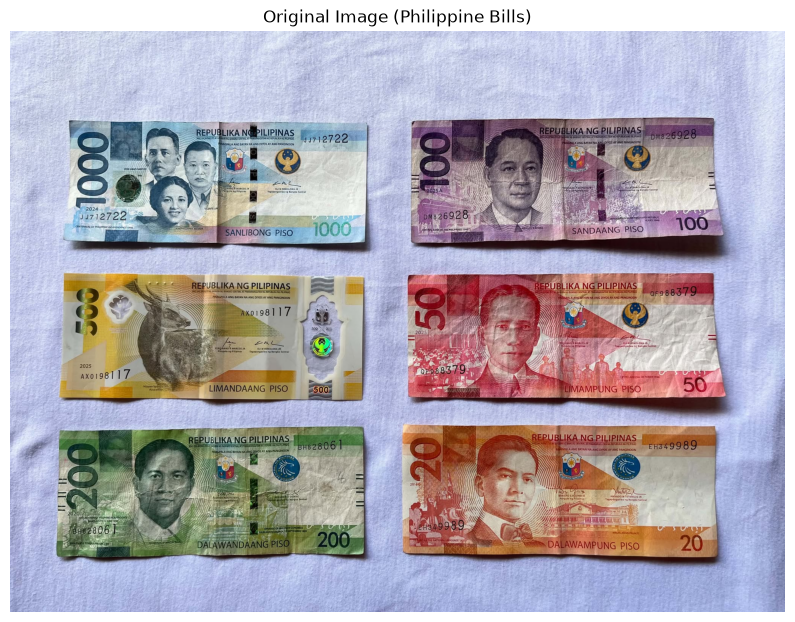

In [20]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load image
image = cv2.imread('paper_bills.jpg')
if image is None:
    raise FileNotFoundError("Image not found. Check the filename or path.")

# Convert BGR to RGB and HSV
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image_hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

# Display original image
plt.figure(figsize=(10, 8))
plt.imshow(image_rgb)
plt.title("Original Image (Philippine Bills)")
plt.axis("off")
plt.show()

## **Part 2: Define Calibrated HSV Ranges**
* **Goal:** Set precise lower and upper boundaries for Hue, Saturation, and Value channels.
* **Process:** Establishes color range dictionaries for each denomination:
  * **1000 Peso:** Light Blue / Cyan
  * **500 Peso:** Yellow / Gold
  * **200 Peso:** Bright Green
  * **100 Peso:** Purple / Violet
  * **50 Peso:** Red (Hue 0–5 & 170–180)
  * **20 Peso:** Orange (Hue 6–18)

In [29]:
# HSV Ranges for Philippine Banknotes (H: 0-180, S: 0-255, V: 0-255)
hsv_ranges = {
    "1000 Peso": {
        "color_box": (0, 191, 255),    # Deep Sky Blue
        "lower": np.array([85, 35, 70]),
        "upper": np.array([105, 255, 255])
    },
    "500 Peso": {
        "color_box": (255, 215, 0),    # Gold/Yellow
        "lower": np.array([20, 60, 80]),
        "upper": np.array([35, 255, 255])
    },
    "200 Peso": {
        "color_box": (0, 255, 0),      # Green
        "lower": np.array([36, 40, 50]),
        "upper": np.array([80, 255, 255])
    },
    "100 Peso": {
        "color_box": (148, 0, 211),    # Purple
        "lower": np.array([125, 30, 50]),
        "upper": np.array([155, 255, 255])
    },
    "50 Peso": {
        "color_box": (255, 0, 0),      # Red
        "lower1": np.array([0, 80, 80]),
        "upper1": np.array([5, 255, 255]),
        "lower2": np.array([172, 80, 80]),
        "upper2": np.array([180, 255, 255])
    },
    "20 Peso": {
        "color_box": (255, 140, 0),    # Orange
        "lower": np.array([6, 60, 60]),
        "upper": np.array([18, 255, 255])
    }
}

## **Part 3: Segmentation & Morphological Union**
* **Goal:** Extract individual binary masks and bridge gaps created by paper creases/folds.
* **Process:** Uses `cv2.inRange` for color segmentation. Applies a rectangular kernel (`35x35`) with `cv2.MORPH_CLOSE` and `cv2.dilate` to connect split regions (such as folded bills) into a single continuous shape[cite: 11].

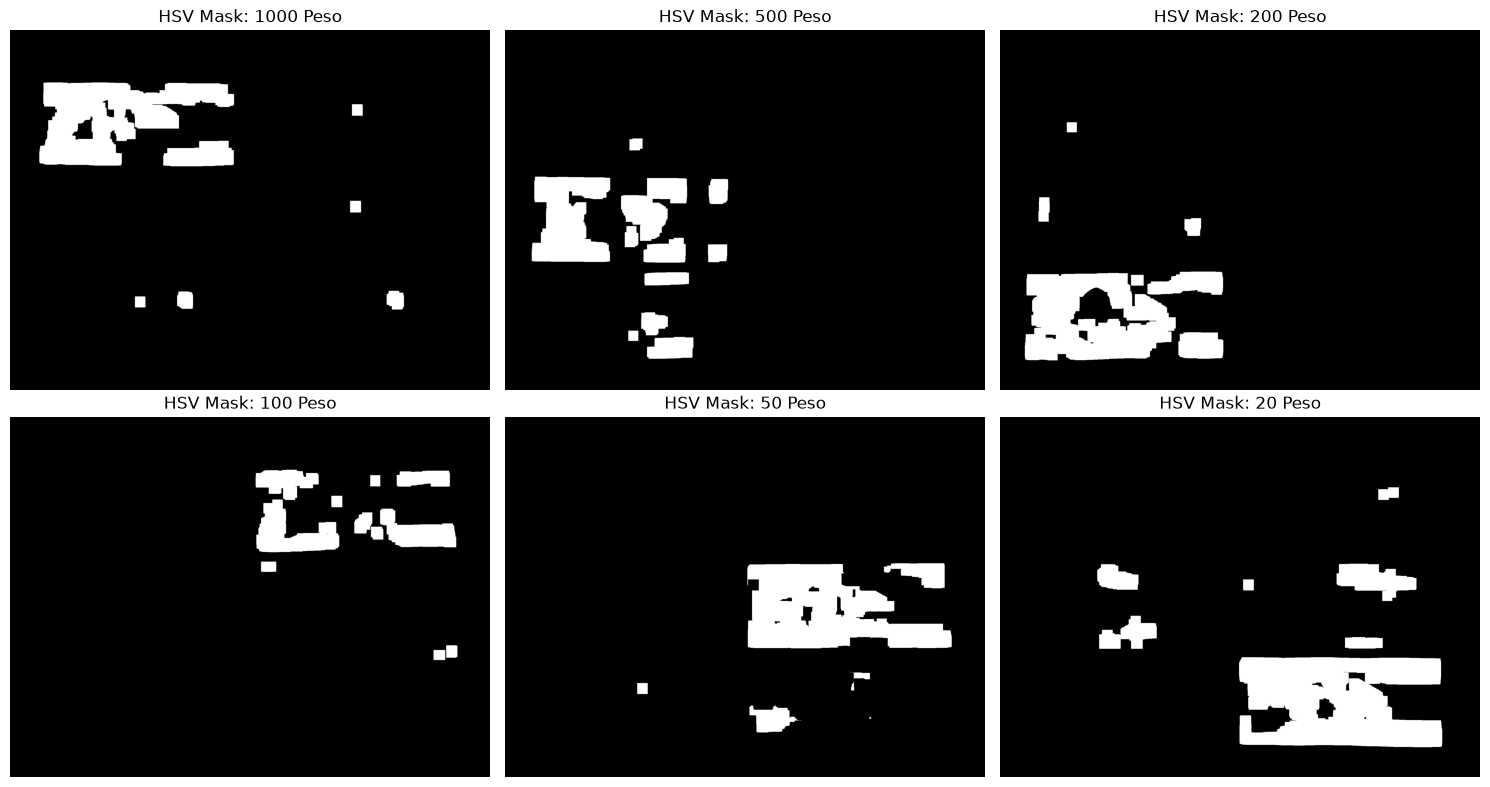

In [30]:
fig, axs = plt.subplots(2, 3, figsize=(15, 8))
axs = axs.ravel()

# Kernel sizes to bridge fold lines
kernel_open = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))
kernel_close = cv2.getStructuringElement(cv2.MORPH_RECT, (35, 35))

masks = {}

for denom, params in hsv_ranges.items():
    if denom == "50 Peso":
        mask1 = cv2.inRange(image_hsv, params["lower1"], params["upper1"])
        mask2 = cv2.inRange(image_hsv, params["lower2"], params["upper2"])
        mask = cv2.bitwise_or(mask1, mask2)
    else:
        mask = cv2.inRange(image_hsv, params["lower"], params["upper"])
    
    # 1. Open to remove small noise
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_open)
    
    # 2. Close with larger kernel to bridge fold lines
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel_close)
    mask = cv2.dilate(mask, kernel_close, iterations=1)
    
    masks[denom] = mask

# Clean overlap: Siguraduhing hiwalay ang 50 Peso sa 20 Peso
masks["50 Peso"] = cv2.bitwise_and(masks["50 Peso"], cv2.bitwise_not(masks["20 Peso"]))

# Display individual binary masks
for idx, (denom, mask) in enumerate(masks.items()):
    axs[idx].imshow(mask, cmap='gray')
    axs[idx].set_title(f"HSV Mask: {denom}")
    axs[idx].axis("off")

plt.tight_layout()
plt.show()

## **Part 4: Contour Extraction & Bounding Box Annotation**
* **Goal:** Detect object boundaries, filter out small artifacts, and overlay color-coded bounding boxes.
* **Process:** Finds contours using `cv2.findContours`. Applies a minimum area filter (`area > 40,000`) so that only full banknote surfaces are annotated. Merges overlapping bounding boxes if any remain.

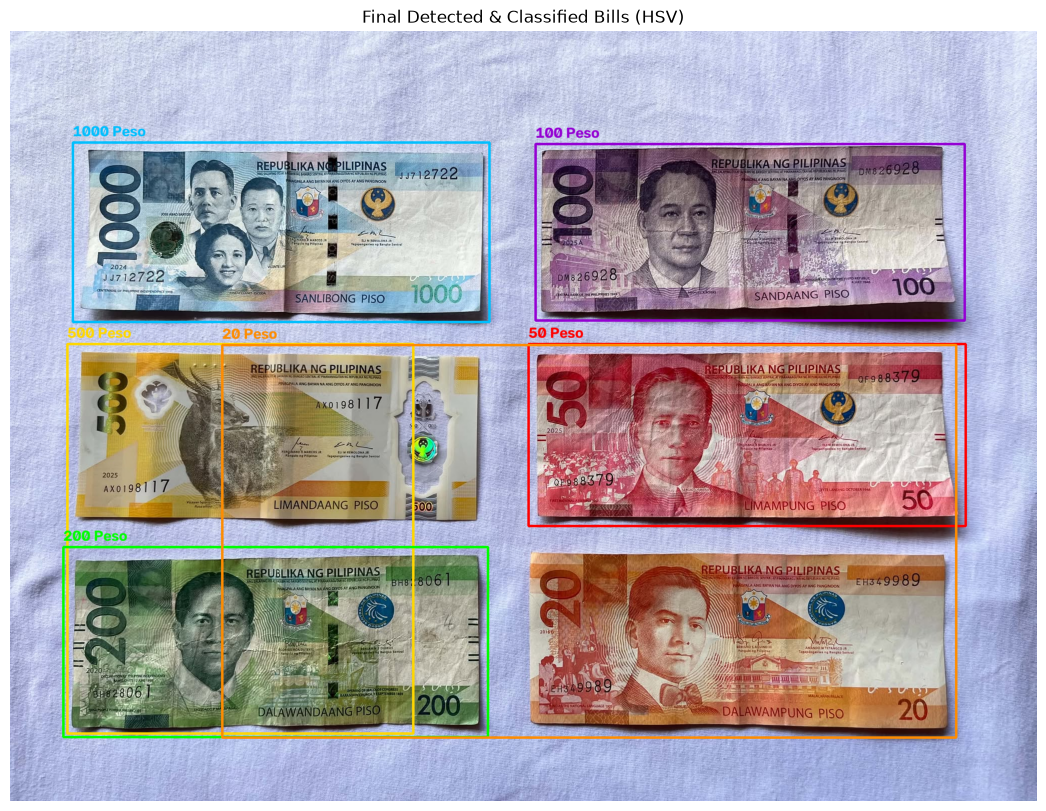

In [34]:
output_img = image_rgb.copy()
bill_counts = {denom: 0 for denom in hsv_ranges.keys()}
total_value = 0

value_map = {
    "1000 Peso": 1000,
    "500 Peso": 500,
    "200 Peso": 200,
    "100 Peso": 100,
    "50 Peso": 50,
    "20 Peso": 20
}

# Area cutoff to ignore small residual fragments
MIN_BILL_AREA = 40000

for denom, mask in masks.items():
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    # Merge contours if multiple fragments exist for the same bill
    if contours:
        valid_contours = [cnt for cnt in contours if cv2.contourArea(cnt) > 15000]
        
        if valid_contours:
            # Combine all valid points for this denomination
            all_points = np.vstack(valid_contours)
            x, y, w, h = cv2.boundingRect(all_points)
            
            # Check combined total area
            if w * h > MIN_BILL_AREA:
                color = hsv_ranges[denom]["color_box"]
                
                # Draw bounding box around full bill
                cv2.rectangle(output_img, (x, y), (x + w, y + h), color, 4)
                
                # Draw label
                label_text = f"{denom}"
                cv2.putText(output_img, label_text, (x, y - 12), 
                            cv2.FONT_HERSHEY_SIMPLEX, 1.0, color, 3)
                
                bill_counts[denom] += 1
                total_value += value_map[denom]

# Display final annotated result
plt.figure(figsize=(14, 10))
plt.imshow(output_img)
plt.title("Final Detected & Classified Bills (HSV)")
plt.axis("off")
plt.show()

## **Part 5: Detection Summary Report**
* **Goal:** Print the itemized count per denomination and display total monetary value.

In [32]:
print("=========================================")
print("     PHILIPPINE BILLS DETECTION SUMMARY   ")
print("=========================================")
for denom, count in bill_counts.items():
    print(f"{denom:<12} : {count} bill(s)")
print("-----------------------------------------")
print(f"Total Bills Detected : {sum(bill_counts.values())}")
print(f"Total Monetary Value : ₱{total_value:,.2f}")
print("=========================================")

     PHILIPPINE BILLS DETECTION SUMMARY   
1000 Peso    : 1 bill(s)
500 Peso     : 1 bill(s)
200 Peso     : 1 bill(s)
100 Peso     : 1 bill(s)
50 Peso      : 1 bill(s)
20 Peso      : 1 bill(s)
-----------------------------------------
Total Bills Detected : 6
Total Monetary Value : ₱1,870.00
